Risetime Plotting
=================

This notebook contains code for plotting the rise time of the pulse edge from measurements taken using the circuit itself. One of these plots ended up in the paper.

Imports and setup stuff
-----------------------

The following cells contain code loading the measurement data.

In [2]:
import numpy as np
import math
import json
import statistics
from pathlib import Path
from matplotlib import pyplot as plt
%matplotlib inline

In [3]:
meas = {}
for f in Path('../data').glob('*.json'):
    d = json.loads(f.read_bytes())
    d['adc1'] = np.array(d['adc1'])
    d['adc2'] = np.array(d['adc2'])
    d['var1'] = np.array(d['var1'])
    d['var2'] = np.array(d['var2'])
    meas[d['meta']] = d

#for n in sorted(meas):
#    print(n)

Plotting function
-----------------

This is the function that locates and plots the pulse edge.

32
1.2677270889282226 2.399308940342494 6
statistics: 1.2860223770141601 2.4105925083160398 1
Rise time t_r = 0.913 ns
32
1.267380380630493 2.398665578024728 6
statistics: 1.2857454299926756 2.409066152572632 1
Rise time t_r = 0.917 ns
32
1.2670966148376464 2.3987874167306082 6
statistics: 1.2853300094604492 2.4077632427215576 1
Rise time t_r = 0.918 ns
32
1.2682112216949462 2.3986098289489743 6
statistics: 1.2855660438537597 2.4095020294189453 1
Rise time t_r = 0.915 ns
32
1.267426538467407 2.3991623742239816 6
statistics: 1.285616397857666 2.409541368484497 1
Rise time t_r = 0.917 ns
32
1.2678550720214843 2.3980990954807826 6
statistics: 1.2856038093566893 2.4091117858886717 1
Rise time t_r = 0.917 ns
32
1.268588876724243 2.3997459411621094 6
statistics: 1.285260772705078 2.409491014480591 1
Rise time t_r = 0.916 ns
32
1.2675959587097165 2.3981170790536064 6
statistics: 1.2846848487854003 2.4086271286010743 1
Rise time t_r = 0.918 ns
32
1.268097925186157 2.3995939799717494 6
statisti

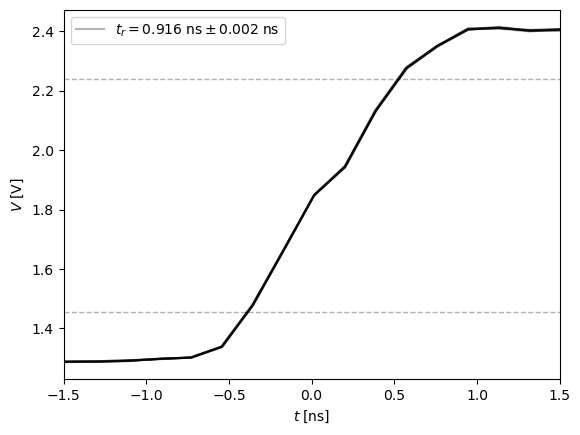

In [4]:
def plot_and_calc(run, ivl_start, ivl_end, ax=None, ylabel=True, grid=True):
    if ax is None:
        fig, ax = plt.subplots()
        
    risetimes = []
    th_lows, th_highs = [], []
    for key in meas.keys():
        if not key.startswith(run):
            continue
        d = meas[key]
        sampling_period_ns = 1000 / 168 / 32
        t = np.linspace(0, len(d['adc1'])*sampling_period_ns, len(d['adc1']))
        ivl_w = ivl_end - ivl_start
        ivl = (ivl_start - ivl_w*0.5, ivl_end + ivl_w*0.5)
    
        t_slice = t[(ivl[0] <= t) & (t <= ivl[1])]
        adc1_slice = d['adc1'][(ivl[0] < t) & (t < ivl[1])]
        print(len(t_slice))
    
        def find_offset(t, y):
            y_sorted = sorted(y)
            low = statistics.mean(y_sorted[:len(y_sorted)//5])
            high = statistics.mean(y_sorted[-len(y_sorted)//5:])
            print(low, high, len(y_sorted)//5)
            amp = high - low
            th = low + 0.5 * amp
            
            for t1, t2, y1, y2 in zip(t, t[1:], y, y[1:]):
                if y1 <= th < y2:
                    return t1 + (t2 - t1) * (th - y1) / (y2 - y1)
    
        t1 = t_slice - find_offset(t_slice, adc1_slice)
    
        sel = (t1 >= -ivl_w/2) & (t1 <= ivl_w/2)
        a, b = sel.argmax(), len(sel) - sel[::-1].argmax()
        t1, adc1_slice = t1[a-1:b+1], adc1_slice[a-1:b+1]
        
        def edge_process(xs, ys, color):
            y_sorted = sorted(ys)
            low = statistics.mean(y_sorted[:len(y_sorted)//10])
            high = statistics.mean(y_sorted[-len(y_sorted)//10:])
            print('statistics:', low, high, len(y_sorted)//10)
            amp = high - low
            th_low = low + 0.15 * amp
            th_high = low + 0.85 * amp
        
            x_low, x_high = None, None
            state = -1
            for x1, x2, y1, y2 in zip(xs, xs[1:], ys, ys[1:]):
                if state == -1 and y1 < th_low and y2 > th_low:
                    x_low = x1 + (x2 - x1) * (th_low - y1) / (y2 - y1)
                    state = 0
                if state == 0 and y1 < th_high and y2 > th_high:
                    state = 1
                    x_high = x1 + (x2 - x1) * (th_high - y1) / (y2 - y1)
            #ax.axvline(x_low, color='red')
            #ax.axvline(x_high, color='blue')
            if x_high is None or x_low is None:
                return 0, 0, 1
            tr = x_high - x_low
            print(f'Rise time t_r = {tr:.3f} ns')
            #ax.axvline(x_low)
            #ax.axvline(x_high)
            return th_low, th_high, tr
            
        
        th_low1, th_high1, tr1 = edge_process(t1, adc1_slice, 'red')
        risetimes.append(tr1)
        
        th_lows.append(th_low1)
        th_highs.append(th_high1)
            
        #ax.plot(t, d['adc1'], color='red', alpha=0.8)
        #ax.twinx().plot(t, d['adc2'], color='blue', alpha=0.8)
        #ax.set_xlim(ivl)
        l1 = ax.plot(t1, adc1_slice, color='black', linestyle='-', alpha=0.3)
        ax.set_xlim([-ivl_w/2, ivl_w/2])
        ax.set_xlabel(r'$t\;[\mathrm{ns}]$')
        if ylabel:
            ax.set_ylabel(r'$V\;[\mathrm{V}]$')
    ax.legend(l1, [
        fr'$t_r = {statistics.mean(risetimes):.3f}\;\mathrm{{ns}} \pm {statistics.stdev(risetimes):.3f}\;\mathrm{{ns}}$'])
    if not grid:
        ax.axhline(statistics.mean(th_lows), linewidth=1, linestyle='--', color='black', alpha=0.3, zorder=-2)
        ax.axhline(statistics.mean(th_highs), linewidth=1, linestyle='--', color='black', alpha=0.3, zorder=-2)
            
#plot_and_calc('pi3hdx_clipline_risetime_new', 87, 90)
plot_and_calc('risetime_74lvc_', 74, 77, grid=False)
#plot_and_calc('run3_max3748_open', 98, 103)
#plot_and_calc('run3_74lvc_open', 97, 103)

Risetime plots for the paper
----------------------------

The cell below plots the figure for the paper that compares the risetime of the four drivers as measured by the board itself.

32
1.2677270889282226 2.399308940342494 6
statistics: 1.2860223770141601 2.4105925083160398 1
Rise time t_r = 0.913 ns
32
1.267380380630493 2.398665578024728 6
statistics: 1.2857454299926756 2.409066152572632 1
Rise time t_r = 0.917 ns
32
1.2670966148376464 2.3987874167306082 6
statistics: 1.2853300094604492 2.4077632427215576 1
Rise time t_r = 0.918 ns
32
1.2682112216949462 2.3986098289489743 6
statistics: 1.2855660438537597 2.4095020294189453 1
Rise time t_r = 0.915 ns
32
1.267426538467407 2.3991623742239816 6
statistics: 1.285616397857666 2.409541368484497 1
Rise time t_r = 0.917 ns
32
1.2678550720214843 2.3980990954807826 6
statistics: 1.2856038093566893 2.4091117858886717 1
Rise time t_r = 0.917 ns
32
1.268588876724243 2.3997459411621094 6
statistics: 1.285260772705078 2.409491014480591 1
Rise time t_r = 0.916 ns
32
1.2675959587097165 2.3981170790536064 6
statistics: 1.2846848487854003 2.4086271286010743 1
Rise time t_r = 0.918 ns
32
1.268097925186157 2.3995939799717494 6
statisti

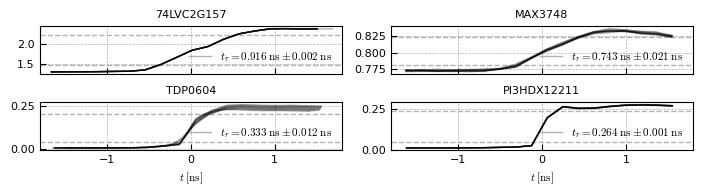

In [5]:
with plt.rc_context({
        'legend.fontsize': 8,
    # RC config from ChatGPT:
    "font.size": 8,  # General font size
    "axes.labelsize": 8,  # Axis labels
    "axes.titlesize": 8,  # Axis titles
    "xtick.labelsize": 8,  # X-axis tick labels
    "ytick.labelsize": 8,  # Y-axis tick labels
    "legend.fontsize": 8,  # Legend font size
    "figure.titlesize": 12,  # Overall figure title
    "mathtext.fontset": "cm",  # Use Computer Modern for math

    # Line and Marker settings
    "lines.linewidth": 1,
    "lines.markersize": 3,

    # Tick settings
    "xtick.major.size": 4,
    "xtick.minor.size": 2,
    "ytick.major.size": 4,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Axes settings
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",

    # Legend settings
    "legend.frameon": False,

    # Figure size for single-column figures in print (inches)
#    "figure.figsize": (3.5, 2.5),  # Adjust based on journal specifications
#    "figure.dpi": 300,  # High resolution for print

    # Savefig settings for high-quality output
    "savefig.dpi": 600,  # Ensures high-resolution images
    "savefig.bbox": "tight",  # Trim extra whitespace
    "savefig.transparent": True,  # Avoid background color
}):
    fig, axs = plt.subplots(2, 2, sharex=True, figsize=[7, 2])
    axs = axs.flatten()

    plot_and_calc('risetime_74lvc_', 74, 77, ax=axs[0], ylabel=None, grid=False)
    plot_and_calc('risetime_max3748_', 145, 148, ax=axs[1], ylabel=None, grid=False)
    plot_and_calc('risetime_tdp0604_', 145, 148, ax=axs[2], ylabel=None, grid=False)
    plot_and_calc('risetime_pi3hdx_', 145, 148, ax=axs[3], ylabel=None, grid=False)

    axs[0].set_xlabel(None)
    axs[1].set_xlabel(None)
    
    # axs[0].set_title('74LVC1G157 MUX Gate with Complimentary Outputs')
    # axs[1].set_title('MAX3748 Optical Network Limiting Amplifier')
    # axs[2].set_title('TDP0604 6 Gb/s HDMI Hybrid Redriver')
    # axs[3].set_title('PI3HDX12211 12 Gb/s HDMI Linear Redriver')
    
    axs[0].set_title('74LVC2G157')
    axs[1].set_title('MAX3748')
    axs[2].set_title('TDP0604')
    axs[3].set_title('PI3HDX12211')
    
    for ax in axs:
        ax.get_legend().set_loc('lower right')
    
    # Only do this on the last axis because of sharex=True
    ax.set_xlim([-1.8, 1.8])
    
    #for ax in axs:
    #    ax.grid()
    fig.tight_layout()

fig.savefig('../../paper/fig_edge_risetime.pdf')

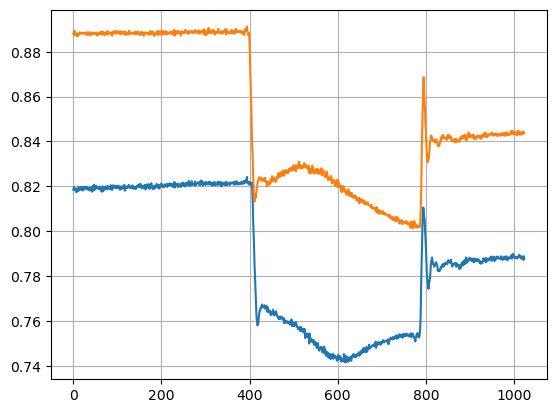

In [7]:
# just out of curiousity:
d = meas['max3748_new2_risetime']
fig, ax = plt.subplots()
ax.grid()
ax.plot(d['adc1'])
ax.plot(d['adc2'])